# Vector search from first principles: what a vector database computes

**Objective:** show that I understand what a vector database *computes*, not just how to call it.

A vector database does one calculation: it **scores a query vector against stored vectors and returns the best _k_**.
Everything else, such as indexes, clusters and APIs, is about doing that calculation faster or on fewer vectors.

This notebook is **self-contained**: every piece of code lives here, and nothing is imported from other project files.

| Part | Task |
|---|---|
| 0 | Setup: libraries, configuration, connection to Qdrant, the 1,000 vectors |
| 1 | The class example by hand: (2,3), (1,2), (0,4) with query (2,4), Euclidean and cosine, both rankings |
| 2 | Brute-force top-k in NumPy, both metrics, over 1,000 vectors of 3072 dimensions |
| 3 | The same queries in Qdrant; show the results match NumPy |
| 4 | Normalise the vectors and show why cosine and dot product then give the same ranking |
| 5 | Time brute force against Qdrant for 1,000 and 10,000 vectors |
| 6 | What an HNSW index changes, with a toy graph search you can watch |
| 7 | Summary |

### The two scores used throughout

**Euclidean distance**, the straight-line gap between two points (*smaller = closer*):

$$d(a,b) = \sqrt{\sum_{i=1}^{n} (a_i - b_i)^2}$$

**Cosine similarity**, the cosine of the angle between two arrows from the origin (*bigger = closer*, range −1 to 1):

$$\cos(a,b) = \frac{a \cdot b}{|a|\,|b|} = \frac{\sum_i a_i b_i}{\sqrt{\sum_i a_i^2}\,\sqrt{\sum_i b_i^2}}$$

---
## Part 0: Setup

### 0.1 Libraries

| Library | Used for |
|---|---|
| `math` | square roots in the by-hand example (no NumPy there, on purpose) |
| `numpy` | vectors, matrix products, brute-force search |
| `pandas` | readable result tables |
| `matplotlib` | plots |
| `requests` | raw HTTP calls (Gemini embeddings, Qdrant server-side timing) |
| `python-dotenv` | reads API keys from the `.env` file so they never appear in the notebook |
| `qdrant-client` | the official Python client for the Qdrant vector database |

Install once with `pip install numpy pandas matplotlib requests python-dotenv qdrant-client`.

In [59]:
import os                                   # read environment variables (API keys, URLs)
import re                                   # regular expressions, used to clean text chunks
import glob                                 # find the SENTINEL chunk files on disk
import json                                 # save and load cached text
import math                                 # sqrt for the by-hand example in Part 1
import time                                 # perf_counter() for timing in Part 5
import statistics                           # median and mean for the timing results

import numpy as np                          # arrays and fast linear algebra
import pandas as pd                         # tables for displaying results
import matplotlib.pyplot as plt             # plotting
import requests                             # plain HTTP requests
from dotenv import load_dotenv              # loads key=value pairs from .env into os.environ
from qdrant_client import QdrantClient, models   # Qdrant client and its configuration models

print("numpy", np.__version__, "| pandas", pd.__version__)   # show versions for reproducibility

numpy 2.5.4 | pandas 3.1.1


### 0.2 Configuration

Settings come from a `.env` file next to this notebook. **The notebook adapts to what's configured:**

- **`QDRANT_API_KEY` set** → it connects to the **Qdrant Cloud** cluster in `QDRANT_URL`. **Empty** → **local Docker** Qdrant
  (`docker run -p 6333:6333 -p 6334:6334 qdrant/qdrant:v1.20.0`).
- **`EURI_API_KEY` set** → the 1,000 vectors are real **Gemini Embedding 2** embeddings of SENTINEL text chunks. **Empty** → 1,000 **synthetic** vectors with the same shape (3072 dims).

In [60]:
load_dotenv(".env")                                          # load .env from the notebook's folder into os.environ

DIM = 3072                                                   # Gemini Embedding 2 output size: 3072 numbers per vector
N_DOCS = 1000                                                # how many stored vectors the main experiments use

EURI_API_KEY = os.getenv("EURI_API_KEY", "").strip()         # Euron gateway key for Gemini embeddings ("" = not set)
EURI_BASE_URL = os.getenv("EURI_BASE_URL", "https://api.euron.one/api/v1/euri")  # gateway address
EMBED_MODEL = os.getenv("EMBED_MODEL", "gemini-embedding-2") # embedding model name
CHUNKS_GLOB = os.getenv(                                     # where the SENTINEL text chunks live on disk
    "CHUNKS_GLOB",                                           # name of the optional override variable
    r"C:\Users\sudha\Downloads\Sentinel project data\sentinel_data\tables\document_chunks\*\*.csv.gz",  # default path
)

QDRANT_API_KEY = os.getenv("QDRANT_API_KEY", "").strip() or None   # cloud key, or None when empty
QDRANT_URL = (os.getenv("QDRANT_URL", "").strip()                  # cloud cluster URL from .env...
              if QDRANT_API_KEY else "http://127.0.0.1:6333")      # ...but only if a key exists; otherwise local Docker

print("Qdrant  :", "Qdrant Cloud" if QDRANT_API_KEY else "local Docker", "->", QDRANT_URL.split("//")[1][:40])  # where we connect
print("Vectors :", "Gemini Embedding 2" if EURI_API_KEY else "synthetic (no EURI_API_KEY in .env)")             # which data we use

Qdrant  : Qdrant Cloud -> 7bd4efab-1390-495c-b723-afd052a2ad34.sa-
Vectors : Gemini Embedding 2


### 0.3 Plot style

Every chart uses one fixed, colour-blind-checked palette, so the same colour always means the same thing:
**blue** = stored vectors or NumPy, **orange** = the query or Qdrant's exact scan, **green** = normalised vectors or HNSW.

In [61]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"         # three series colours, always in this order
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"   # text, secondary text, axis labels, gridlines
plt.rcParams.update({                                        # global matplotlib settings for every plot below
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",   # off-white background for figure and plot area
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,         # soft axis lines, grey axis labels
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, # dark titles, muted tick labels
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,  # thin, light gridlines
    "axes.spines.top": False, "axes.spines.right": False,          # remove the top and right frame lines
    "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold",  # readable on a video frame
    "figure.dpi": 110,                                              # sharp enough for screen recording
})
pd.set_option("display.precision", 4)                       # show 4 decimals in pandas tables

### 0.4 Connect to Qdrant

We use **gRPC** (port 6334) instead of REST (port 6333) for loading data, because gRPC sends vectors as binary floats.
REST sends them as JSON text, about 65 KB per 3072-number vector.

In [62]:
client = QdrantClient(                     # create one client and reuse it everywhere
    url=QDRANT_URL,                        # cloud URL or http://127.0.0.1:6333
    api_key=QDRANT_API_KEY,                # None for local Docker
    prefer_grpc=True,                      # use gRPC (binary) instead of REST (JSON) where possible
    timeout=300,                           # seconds; uploads of 10,000 vectors can take a while
)
existing = [c.name for c in client.get_collections().collections]   # list collections: also proves the connection works
print("connected; existing collections:", existing)                # show what is already on the server

connected; existing collections: ['part3_numpy_vs_qdrant', 'part4_normalise', 'sentinel_docs']


### 0.5 The 1,000 stored vectors and 5 query vectors

**Real embeddings (`EURI_API_KEY` set):** pick 1,000 distinct SENTINEL text chunks, remove a repeated banner, cut each to ~300 characters
(about 75k tokens in total, inside the API's daily limit), and embed them with Gemini Embedding 2 at 3072 dims. Gemini expects a task prefix:
`title: none | text: …` for documents and `task: search result | query: …` for questions. The result is cached in `data/`, so the API runs only once.

**Synthetic vectors (no key):** 40 random "topic" directions in 3072-D space. Each stored vector is one topic plus noise, scaled to a **random length between 0.5 and 2**.
The random lengths are deliberate: without them, raw dot product and cosine would already agree, and Part 4 would have nothing to show.

In [64]:
QUERIES = [                                                                  # five search questions (used as text only with real embeddings)
    "unauthorised UPI payment late at night after several failed attempts",  # query 0
    "new device login followed by a sudden spike in transaction amount",     # query 1
    "what evidence should an investigator collect for a chargeback dispute", # query 2
    "regulatory exercise on reporting suspicious transactions",              # query 3
    "playbook steps for handling a suspected account takeover",              # query 4
]


def synthetic_vectors(n, n_queries=5, dim=DIM, n_topics=40, seed=0):  # n stored + n_queries query vectors
    """Clustered random vectors with the same shape as Gemini Embedding 2 output."""
    rng = np.random.default_rng(seed)                                        # seeded generator, so results repeat exactly
    topics = rng.normal(size=(n_topics, dim))                                # 40 random directions in 3072-D space
    topics /= np.linalg.norm(topics, axis=1, keepdims=True)                  # make each topic direction length 1
    label = rng.integers(0, n_topics, size=n)                                # assign every stored vector to a random topic
    X = topics[label] + rng.normal(scale=0.8 / np.sqrt(dim), size=(n, dim))  # topic direction + noise of length ~0.8
    X /= np.linalg.norm(X, axis=1, keepdims=True)                            # scale to length 1 first...
    X *= rng.uniform(0.5, 2.0, size=(n, 1))                                  # ...then to a random length 0.5-2.0
    Q = topics[:n_queries] + rng.normal(scale=0.8 / np.sqrt(dim), size=(n_queries, dim))  # queries = first topics + noise
    return X.astype(np.float32), Q.astype(np.float32)                        # float32 = what embedding APIs and Qdrant use


def embed(texts):  # input: list of strings, output: list of 3072-number vectors
    """Embed a list of strings with Gemini Embedding 2 via the Euron gateway (OpenAI-style /embeddings)."""
    for attempt in range(6):                                                 # retry up to 6 times on rate limits
        r = requests.post(                                                   # one HTTP POST per batch
            f"{EURI_BASE_URL}/embeddings",                                   # endpoint
            headers={"Authorization": f"Bearer {EURI_API_KEY}"},             # API key goes in the header, never in the URL
            json={"model": EMBED_MODEL, "input": texts, "dimensions": DIM},  # model, batch of texts, 3072 dims
            timeout=120,                                                     # give up on a hung request after 2 minutes
        )
        if r.status_code == 429:                                             # 429 = rate limited
            time.sleep(5 * 2 ** attempt)                                     # wait 5, 10, 20... seconds, then retry
            continue                                                         # try the same batch again
        r.raise_for_status()                                                 # any other error stops the notebook loudly
        data = sorted(r.json()["data"], key=lambda d: d["index"])            # keep vectors in the same order as the inputs
        return [d["embedding"] for d in data]                                # list of 3072-number lists
    raise RuntimeError("still rate limited after 6 tries")                   # give up after all retries


def gemini_vectors():  # returns (docs, queries, texts), using the cache when present
    """1,000 SENTINEL chunks + 5 queries embedded once, then cached in data/."""
    os.makedirs("data", exist_ok=True)                                       # cache folder
    if not os.path.exists("data/docs.npy"):                                  # embed only on the very first run
        banner = re.compile(r"SYNTHETIC TRAINING MATERIAL\..*?production model output\.\s*", re.S)  # repeated header text
        df = pd.concat(pd.read_csv(f) for f in glob.glob(CHUNKS_GLOB))       # read every chunk file into one table
        clean = lambda t: re.sub(r"\s+", " ", banner.sub("", t).replace("#", "")).strip()[:300]    # drop banner, cut to 300 chars
        texts = df.content.map(clean).drop_duplicates().sample(N_DOCS, random_state=42).tolist()   # 1,000 distinct chunks
        vecs = []                                                            # collected embeddings
        for i in range(0, len(texts), 16):                                   # 16 texts per request
            vecs += embed([f"title: none | text: {t}" for t in texts[i:i + 16]])  # Gemini's document prefix
        np.save("data/docs.npy", np.array(vecs, np.float32))                 # cache document vectors
        np.save("data/queries.npy", np.array(embed([f"task: search result | query: {q}" for q in QUERIES]), np.float32))  # query vectors
        json.dump(texts, open("data/texts.json", "w", encoding="utf-8"))     # cache the texts, to show what was found
    texts = json.load(open("data/texts.json", encoding="utf-8"))             # load cached texts
    return np.load("data/docs.npy"), np.load("data/queries.npy"), texts      # load cached vectors


if EURI_API_KEY:                                                             # real embeddings available?
    X, Q, texts = gemini_vectors()                                           # yes: Gemini Embedding 2
    SOURCE = "Gemini Embedding 2"                                            # label for printouts
else:                                                                        # no key
    X, Q = synthetic_vectors(N_DOCS)                                         # synthetic stand-in vectors
    texts, SOURCE = None, "synthetic"                                        # no texts to show

lengths = np.linalg.norm(X, axis=1)                                          # length |x| of every stored vector
print(f"stored vectors X: {X.shape}  query vectors Q: {Q.shape}  source: {SOURCE}")   # shapes: (1000, 3072) and (5, 3072)
print(f"vector lengths: min {lengths.min():.3f}, max {lengths.max():.3f}")          # synthetic: 0.5-2.0, Gemini: ~1.0
print("first 5 numbers of vector 0:", X[0, :10].round(4))                           # a vector is just a list of numbers

stored vectors X: (1000, 3072)  query vectors Q: (5, 3072)  source: Gemini Embedding 2
vector lengths: min 1.000, max 1.000
first 5 numbers of vector 0: [-0.0014  0.0139  0.0022  0.0195 -0.0028  0.0135 -0.019   0.0024  0.0026
 -0.0315]


---
## Part 1: The class example by hand

Three stored points and one query, in 2D so we can draw them:

| point | vector |
|---|---|
| A | (2, 3) |
| B | (1, 2) |
| C | (0, 4) |
| **query q** | **(2, 4)** |

We use plain Python, **no NumPy**, so every step is visible.

**Worked by hand** (|q| = √(2² + 4²) = √20 ≈ 4.472):

| point | Euclidean to q | cosine with q |
|---|---|---|
| A (2,3) | √((2−2)² + (3−4)²) = √1 = **1.000** | (2·2 + 3·4) / (√13 · √20) = 16 / 16.125 = 0.992 |
| B (1,2) | √((1−2)² + (2−4)²) = √5 = 2.236 | (1·2 + 2·4) / (√5 · √20) = 10 / 10 = **1.000** |
| C (0,4) | √((0−2)² + (4−4)²) = √4 = 2.000 | (0·2 + 4·4) / (√16 · √20) = 16 / 17.889 = 0.894 |

In [65]:
points = {"A": (2, 3), "B": (1, 2), "C": (0, 4)}   # the three stored 2D vectors
q = (2, 4)                                          # the query vector


def dot(a, b):                                      # dot product: a1*b1 + a2*b2 + ...
    return sum(x * y for x, y in zip(a, b))         # multiply matching coordinates, then add them up


def length(a):                                      # length (norm) |a| = sqrt(a . a)
    return math.sqrt(dot(a, a))                     # Pythagoras: sqrt(a1^2 + a2^2 + ...)


def euclidean(a, b):                                # straight-line distance between two points
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))   # sqrt of the summed squared differences


def cosine(a, b):                                   # cosine of the angle between a and b
    return dot(a, b) / (length(a) * length(b))      # dot product divided by both lengths


print(f"q = {q}, |q| = sqrt(2^2 + 4^2) = sqrt(20) = {length(q):.4f}\n")   # length of the query, used by every cosine
for name, p in points.items():                      # walk through A, B and C
    dx2, dy2 = (p[0] - q[0]) ** 2, (p[1] - q[1]) ** 2   # squared differences in x and in y
    print(f"{name} = {p}")                          # which point
    print(f"   Euclidean = sqrt(({p[0]}-2)^2 + ({p[1]}-4)^2) = sqrt({dx2} + {dy2}) = {euclidean(p, q):.4f}")  # the distance, step by step
    print(f"   cosine    = ({p[0]}*2 + {p[1]}*4) / ({length(p):.4f} * {length(q):.4f})"   # numerator and denominator...
          f" = {dot(p, q)} / {length(p) * length(q):.4f} = {cosine(p, q):.4f}")   # the cosine, step by step

q = (2, 4), |q| = sqrt(2^2 + 4^2) = sqrt(20) = 4.4721

A = (2, 3)
   Euclidean = sqrt((2-2)^2 + (3-4)^2) = sqrt(0 + 1) = 1.0000
   cosine    = (2*2 + 3*4) / (3.6056 * 4.4721) = 16 / 16.1245 = 0.9923
B = (1, 2)
   Euclidean = sqrt((1-2)^2 + (2-4)^2) = sqrt(1 + 4) = 2.2361
   cosine    = (1*2 + 2*4) / (2.2361 * 4.4721) = 10 / 10.0000 = 1.0000
C = (0, 4)
   Euclidean = sqrt((0-2)^2 + (4-4)^2) = sqrt(4 + 0) = 2.0000
   cosine    = (0*2 + 4*4) / (4.0000 * 4.4721) = 16 / 17.8885 = 0.8944


In [66]:
euc = {n: euclidean(p, q) for n, p in points.items()}          # Euclidean distance of every point to q
cos = {n: cosine(p, q) for n, p in points.items()}             # cosine similarity of every point with q

by_euc = sorted(euc, key=euc.get)                              # smallest distance first (closest first)
by_cos = sorted(cos, key=cos.get, reverse=True)                # largest cosine first (most similar first)

print("Ranking by Euclidean distance (smaller = closer):")     # header
for rank, n in enumerate(by_euc, 1):                           # rank 1, 2, 3
    print(f"   {rank}. {n} {points[n]}  distance = {euc[n]:.4f}")   # point and its distance
print("\nRanking by cosine similarity (larger = closer):")     # header
for rank, n in enumerate(by_cos, 1):                           # rank 1, 2, 3
    print(f"   {rank}. {n} {points[n]}  cosine = {cos[n]:.4f}")     # point and its cosine

Ranking by Euclidean distance (smaller = closer):
   1. A (2, 3)  distance = 1.0000
   2. C (0, 4)  distance = 2.0000
   3. B (1, 2)  distance = 2.2361

Ranking by cosine similarity (larger = closer):
   1. B (1, 2)  cosine = 1.0000
   2. A (2, 3)  cosine = 0.9923
   3. C (0, 4)  cosine = 0.8944


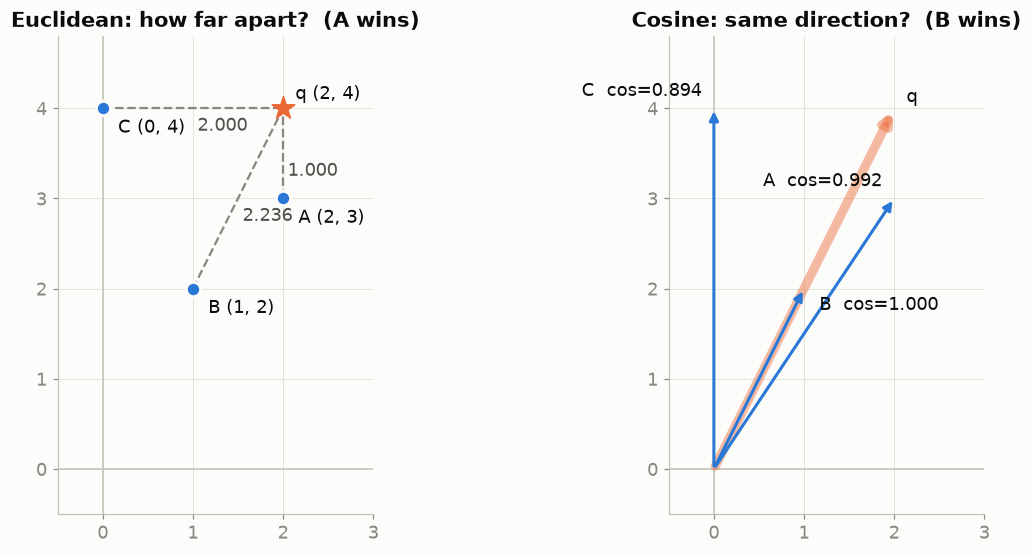

In [67]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2))       # two plots side by side
P = np.array(list(points.values()), float)                     # the three points as a 3x2 array, for plotting

# ---- left: Euclidean = length of the dashed line between the points
for (name, p) in points.items():                               # one dashed line per stored point
    ax1.plot([p[0], q[0]], [p[1], q[1]], "--", color=MUTED, lw=1.5)   # line from the point to q
    ax1.text((p[0] + q[0]) / 2 + 0.05, (p[1] + q[1]) / 2 - 0.25, f"{euc[name]:.3f}", color=INK2)  # distance at the middle
    ax1.annotate(f"{name} {p}", p, textcoords="offset points", xytext=(10, -16))   # name label next to the point
ax1.scatter(P[:, 0], P[:, 1], s=90, color=BLUE, zorder=3, edgecolor="#fcfcfb", lw=2)  # stored points in blue
ax1.scatter(*q, s=240, marker="*", color=ORANGE, zorder=4)     # the query as an orange star
ax1.annotate("q (2, 4)", q, textcoords="offset points", xytext=(8, 6))   # query label
ax1.set_title("Euclidean: how far apart?  (A wins)")           # what this panel shows

# ---- right: cosine = the angle between arrows from the origin
ax2.annotate("", xy=q, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=6, alpha=0.45))  # q first, wide and light
for name, p in points.items():                                 # one arrow per stored point, drawn on top of q
    ax2.annotate("", xy=p, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2))   # arrow from the origin
    ax2.annotate(f"{name}  cos={cos[name]:.3f}", p, textcoords="offset points",   # label with the cosine value
                 xytext=(10, -14) if name == "B" else (-8, 8), ha="left" if name == "B" else "right")  # keep B's label off A
ax2.annotate("q", q, textcoords="offset points", xytext=(8, 4))  # query label
ax2.set_title("Cosine: same direction?  (B wins)")              # what this panel shows

for ax in (ax1, ax2):                                          # shared formatting for both panels
    ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 4.8)               # same view in both
    ax.set_aspect("equal")                                     # 1 unit on x = 1 unit on y, so angles look right
    ax.axhline(0, color="#c3c2b7", lw=1); ax.axvline(0, color="#c3c2b7", lw=1)   # draw the x and y axes
plt.tight_layout(); plt.show()                                 # render

**The two metrics disagree, and that is the lesson.**

- Euclidean ranking: **A, C, B**. Cosine ranking: **B, A, C**.
- B = (1, 2) is **exactly half of q** = (2, 4): the same direction with a shorter arrow.
  Cosine looks only at direction, so B is a perfect **1.0**. Euclidean looks at the gap between the points, so B is the **furthest**.
- The maths in 3072 dimensions is identical. Each sum just has 3072 terms instead of 2.

---
## Part 2: Brute-force top-k search in NumPy

**Brute force** = compare the query with **every** stored vector, then keep the best *k*. There's no index, so the answer is **exact**.

The trick that makes it fast: all 1,000 dot products are **one matrix-vector product**, `X @ q`. `X` is 1000×3072 and `q` has 3072 numbers, so the result has 1,000 numbers.

- **Cosine:** `(X @ q) / (|x| · |q|)` → 1,000 cosines at once.
- **Euclidean:** expand $|x - q|^2 = |x|^2 - 2\,x\cdot q + |q|^2$. This reuses the same `X @ q` instead of subtracting q from 1,000 vectors in a loop.
- **Top-k:** `np.argpartition` finds the *k* best in O(n) without sorting all 1,000. Then we sort only those *k*.

In [68]:
K = 5                                                    # how many results to return


def top_k(scores, k, largest):  # scores: one number per stored vector
    """Indices of the k best scores, best first."""
    s = -scores if largest else scores                   # argpartition finds the smallest, so flip the sign for "largest"
    idx = np.argpartition(s, k)[:k]                      # the k best, in no particular order: O(n)
    return idx[np.argsort(s[idx])]                       # sort just those k: O(k log k)


def cosine_topk(X, q, k=K):  # X: (n, 3072) stored vectors, q: (3072,) query
    """Brute force: cosine similarity of q with every row of X, keep the k highest."""
    sims = (X @ q) / (np.linalg.norm(X, axis=1) * np.linalg.norm(q))   # 1,000 dot products / (1,000 lengths x |q|)
    idx = top_k(sims, k, largest=True)                   # bigger cosine = closer
    return idx, sims[idx]                                # row numbers and their scores


def euclidean_topk(X, q, k=K):  # same inputs, smaller-is-better metric
    """Brute force: Euclidean distance from q to every row of X, keep the k smallest."""
    d2 = np.einsum("ij,ij->i", X, X) - 2 * (X @ q) + q @ q   # |x|^2 - 2 x.q + |q|^2 for all rows at once
    dist = np.sqrt(np.maximum(d2, 0))                    # clip tiny negative rounding errors, then take the square root
    idx = top_k(dist, k, largest=False)                  # smaller distance = closer
    return idx, dist[idx]                                # row numbers and their distances

**Sanity check first:** run the new NumPy functions on the 2D class example. They must reproduce Part 1 exactly.

In [69]:
P2 = np.array([[2, 3], [1, 2], [0, 4]], np.float32)     # A, B, C as a NumPy array
q2 = np.array([2, 4], np.float32)                       # the query
names = np.array(["A", "B", "C"])                       # row number -> name
ci, cs = cosine_topk(P2, q2, k=2)                       # top-2 by cosine (k must be < number of rows for argpartition)
ei, ed = euclidean_topk(P2, q2, k=2)                    # top-2 by Euclidean
print("cosine top-2   :", [(str(n), round(float(s), 4)) for n, s in zip(names[ci], cs)])   # expect B (1.0), A (0.9923)
print("Euclidean top-2:", [(str(n), round(float(d), 4)) for n, d in zip(names[ei], ed)])   # expect A (1.0), C (2.0)

cosine top-2   : [('B', 1.0), ('A', 0.9923)]
Euclidean top-2: [('A', 1.0), ('C', 2.0)]


Now the real thing: 1,000 vectors × 3072 dims, 5 queries, both metrics.

In [45]:
numpy_results = {}                                       # keep the results for the comparison with Qdrant in Part 3
rows = []                                                # rows for a display table
for qi, qv in enumerate(Q):                              # each of the 5 query vectors
    c_ids, c_sc = cosine_topk(X, qv)                     # brute-force cosine top-5
    e_ids, e_sc = euclidean_topk(X, qv)                  # brute-force Euclidean top-5
    numpy_results[qi] = {"cosine": (c_ids, c_sc), "euclid": (e_ids, e_sc)}   # store both
    rows.append({                                        # one summary row per query
        "query": qi,                                     # query number
        "cosine top-5 ids": c_ids.tolist(),              # best rows by cosine
        "cosine scores": c_sc.round(4).tolist(),         # their cosine similarities
        "Euclidean top-5 ids": e_ids.tolist(),           # best rows by distance
        "distances": e_sc.round(4).tolist(),             # their distances
        "shared ids": len(set(c_ids) & set(e_ids)),      # how much the two lists agree
    })
pd.DataFrame(rows).set_index("query")                   # show the table

,cosine top-5 ids,cosine scores,Euclidean top-5 ids,distances,shared ids
query,,,,,
0,"[157, 321, 379, 844, 968]","[0.729, 0.7278, 0.7269, 0.7267, 0.7265]","[157, 321, 379, 844, 968]","[0.7363, 0.7379, 0.739, 0.7393, 0.7397]",5
1,"[527, 0, 35, 480, 512]","[0.6963, 0.6738, 0.6717, 0.6706, 0.6696]","[527, 0, 35, 480, 512]","[0.7793, 0.8077, 0.8104, 0.8116, 0.8129]",5
2,"[839, 58, 145, 64, 454]","[0.7351, 0.735, 0.7349, 0.7347, 0.7327]","[839, 58, 145, 64, 454]","[0.7279, 0.728, 0.7282, 0.7284, 0.7312]",5
3,"[35, 953, 723, 775, 690]","[0.7481, 0.7365, 0.7303, 0.727, 0.7253]","[35, 953, 723, 775, 690]","[0.7097, 0.7259, 0.7344, 0.739, 0.7413]",5
4,"[711, 927, 512, 48, 514]","[0.6598, 0.6589, 0.6465, 0.6438, 0.643]","[711, 927, 512, 48, 514]","[0.8249, 0.826, 0.8409, 0.8441, 0.845]",5


In [70]:
if texts:                                                # only with real embeddings: show what the search found
    for qi in range(len(Q)):                             # each query
        best = numpy_results[qi]["cosine"][0][0]         # row number of the best cosine hit
        print(f"Q{qi}: {QUERIES[qi]}\n    -> {texts[best][:120]}...\n")   # question and the start of the best chunk
else:                                                    # synthetic vectors have no text behind them
    print("Synthetic vectors: no text to show. Add EURI_API_KEY to .env to search real SENTINEL chunks.")   # explain why

Q0: unauthorised UPI payment late at night after several failed attempts
    -> Dispute intake and evidence review TX_0000400341 entry 1 Case scope Case reference TX_0000400341; review entry 1. Unauth...

Q1: new device login followed by a sudden spike in transaction amount
    -> Synthetic RBI topic exercise 0821 on device change Purpose Teach evidence-based review of device change for a fictional ...

Q2: what evidence should an investigator collect for a chargeback dispute
    -> Dispute intake and evidence review TX_0000731314 entry 1 Case scope Case reference TX_0000731314; review entry 1. Duplic...

Q3: regulatory exercise on reporting suspicious transactions
    -> Synthetic RBI topic exercise 0185 on new accounts Purpose Teach evidence-based review of new accounts for a fictional ot...

Q4: playbook steps for handling a suspected account takeover
    -> Internal teaching playbook 0570 on customer verification Purpose Teach evidence-based review of customer verification fo...



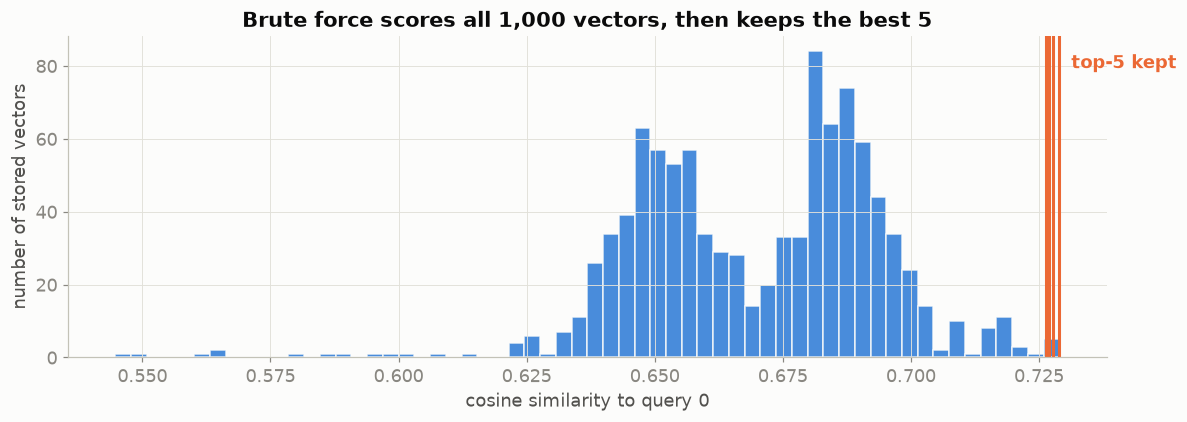

In [71]:
q0 = Q[0]                                                # use query 0 for the picture
all_cos = (X @ q0) / (lengths * np.linalg.norm(q0))      # cosine of query 0 with all 1,000 stored vectors
top_scores = numpy_results[0]["cosine"][1]               # the 5 scores that brute force kept

fig, ax = plt.subplots(figsize=(11, 4))                  # one wide plot
ax.hist(all_cos, bins=60, color=BLUE, alpha=0.85, edgecolor="#fcfcfb")   # distribution of all 1,000 scores
for s in top_scores:                                     # mark every kept score
    ax.axvline(s, color=ORANGE, lw=2)                    # orange line = one of the top 5
ax.text(top_scores[0], ax.get_ylim()[1] * 0.9, f"  top-{K} kept", color=ORANGE, fontweight="bold")   # label the lines
ax.set_xlabel("cosine similarity to query 0")            # x axis
ax.set_ylabel("number of stored vectors")                # y axis
ax.set_title(f"Brute force scores all {len(X):,} vectors, then keeps the best {K}")   # the message of the plot
plt.tight_layout(); plt.show()                           # render

- Most stored vectors are unrelated to the query (the big hump). A few are close (the right tail). Top-k simply picks the far right edge.
- The cosine and Euclidean top-5 lists are **not identical**, because these vectors have different lengths and Euclidean cares about length (Part 1 again).

---
## Part 3: The same queries in Qdrant, and the results match NumPy

We load the same 1,000 vectors into a Qdrant **collection**. Each point stores the vector **twice under two names** ("named vectors"):

| name | Qdrant distance | what Qdrant's score means |
|---|---|---|
| `cos` | `Distance.COSINE` | the cosine similarity (higher = closer) |
| `euc` | `Distance.EUCLID` | the Euclidean distance (lower = closer) |

The **point id = the NumPy row number**, so ids can be compared directly. Every query runs in two modes:

- `exact=True`: Qdrant scans every vector, the same work as our brute force.
- `exact=False`: Qdrant walks its **HNSW graph index**. Qdrant normally *skips* building HNSW for small collections (under ~10 MB it just scans),
  so we lower `indexing_threshold` and `full_scan_threshold` to force a real index even for 1,000 vectors.

In [72]:
def upload(name, vectors):  # name: collection, vectors: array or {name: array}
    """Upload vectors (one array, or a dict of named arrays) with ids 0..n-1."""
    n = len(next(iter(vectors.values()))) if isinstance(vectors, dict) else len(vectors)   # number of points
    client.upload_collection(                            # the client splits the data into batches for us
        collection_name=name,                            # target collection
        vectors=vectors,                                 # the numbers
        ids=list(range(n)),                              # point id = NumPy row number
        batch_size=128,                                  # 128 points per request (well under Qdrant's 32 MB limit)
        wait=True,                                       # return only once the points are stored
    )


def wait_until_indexed(name, n, timeout=600):  # polls the server until the graph is ready
    """Wait until Qdrant's background optimizer has built the HNSW graph for all n points."""
    start = time.time()                                  # for the timeout
    while time.time() - start < timeout:                 # keep checking...
        info = client.get_collection(name)               # collection status from the server
        if info.status == models.CollectionStatus.GREEN and (info.indexed_vectors_count or 0) >= n:  # green and fully indexed?
            return info.indexed_vectors_count            # done: how many vectors are in the graph
        time.sleep(1)                                    # not yet: wait a second
    raise TimeoutError(f"{name} not indexed after {timeout} s")   # something is wrong

In [49]:
C3 = "part3_numpy_vs_qdrant"                             # collection name for this part
if client.collection_exists(C3):                         # left over from an earlier run?
    client.delete_collection(C3)                         # start clean

client.create_collection(                                # define the collection
    collection_name=C3,                                  # its name
    vectors_config={                                     # two named vectors per point
        "cos": models.VectorParams(size=DIM, distance=models.Distance.COSINE),   # scored by cosine
        "euc": models.VectorParams(size=DIM, distance=models.Distance.EUCLID),   # scored by Euclidean distance
    },                                                   # end of the named-vector definitions
    optimizers_config=models.OptimizersConfigDiff(indexing_threshold=10),        # build HNSW once a segment passes 10 KB
    hnsw_config=models.HnswConfigDiff(m=16, ef_construct=100, full_scan_threshold=10),  # graph settings; use HNSW above 10 KB
)
upload(C3, {"cos": X, "euc": X})                         # the same 1,000 vectors under both names
indexed = wait_until_indexed(C3, len(X))                 # wait for the HNSW graph
print(f"{client.count(C3).count} points stored, {indexed} vectors in the HNSW index (1,000 x 2 names)")   # confirm

1000 points stored, 2000 vectors in the HNSW index (1,000 x 2 names)


In [73]:
def qdrant_topk(qv, using, exact, k=K):  # one query, one named vector, one mode
    """Ask Qdrant for the top-k of one query; return (ids, scores)."""
    points = client.query_points(                        # Qdrant's universal search call
        collection_name=C3,                              # which collection
        query=qv.tolist(),                               # the query vector as a plain list
        using=using,                                     # which named vector to search: "cos" or "euc"
        limit=k,                                         # how many results
        search_params=models.SearchParams(exact=exact, hnsw_ef=64),   # exact scan, or HNSW with a 64-candidate shortlist
    ).points                                             # the list of results
    return [p.id for p in points], np.array([p.score for p in points])   # ids and scores, best first


rows = []                                                # one row per comparison
for qi, qv in enumerate(Q):                              # 5 queries
    for metric, using in [("cosine", "cos"), ("euclid", "euc")]:          # x 2 metrics
        np_ids, np_sc = numpy_results[qi][metric]        # our brute-force answer from Part 2
        for mode, exact in [("exact", True), ("HNSW", False)]:            # x 2 Qdrant modes = 20 comparisons
            qd_ids, qd_sc = qdrant_topk(qv, using, exact)                 # Qdrant's answer
            rows.append({                                # record the comparison
                "query": qi, "metric": metric, "Qdrant mode": mode,      # what was compared
                "NumPy ids": np_ids.tolist(), "Qdrant ids": qd_ids,       # both rankings
                "max score diff": float(np.abs(np_sc - qd_sc).max()),     # largest score difference
                "match": np_ids.tolist() == qd_ids and np.allclose(np_sc, qd_sc, atol=1e-4),   # same ids, same order, same scores?
            })
cmp = pd.DataFrame(rows)                                 # table of all 20 comparisons
print(f"{cmp['match'].sum()} of {len(cmp)} comparisons match "   # count of matching comparisons...
      f"(largest score difference: {cmp['max score diff'].max():.1e})")   # headline result
cmp                                                      # show the full table

20 of 20 comparisons match (largest score difference: 3.6e-07)


,query,metric,Qdrant mode,NumPy ids,Qdrant ids,max score diff,match
0,0,cosine,exact,"[157, 321, 379, 844, 968]","[157, 321, 379, 844, 968]",1.1921e-07,True
1,0,cosine,HNSW,"[157, 321, 379, 844, 968]","[157, 321, 379, 844, 968]",1.1921e-07,True
2,0,euclid,exact,"[157, 321, 379, 844, 968]","[157, 321, 379, 844, 968]",2.3842e-07,True
3,0,euclid,HNSW,"[157, 321, 379, 844, 968]","[157, 321, 379, 844, 968]",2.3842e-07,True
4,1,cosine,exact,"[527, 0, 35, 480, 512]","[527, 0, 35, 480, 512]",1.1921e-07,True
5,1,cosine,HNSW,"[527, 0, 35, 480, 512]","[527, 0, 35, 480, 512]",1.1921e-07,True
6,1,euclid,exact,"[527, 0, 35, 480, 512]","[527, 0, 35, 480, 512]",3.5763e-07,True
7,1,euclid,HNSW,"[527, 0, 35, 480, 512]","[527, 0, 35, 480, 512]",3.5763e-07,True
8,2,cosine,exact,"[839, 58, 145, 64, 454]","[839, 58, 145, 64, 454]",3.5763e-07,True
9,2,cosine,HNSW,"[839, 58, 145, 64, 454]","[839, 58, 145, 64, 454]",3.5763e-07,True


**Same ids, in the same order, with the same scores**, for both metrics and both modes.

- Qdrant's `COSINE` score **is** the cosine we computed, and its `EUCLID` score **is** the Euclidean distance. There's no hidden magic.
- The differences of ~1e-7 are float32 rounding: Qdrant adds up the 3072 products in a different order (SIMD) than NumPy.
- HNSW matches here too: with 1,000 vectors and a shortlist of 64, the graph search finds the true top-5. Part 5 shows that it is approximate at larger scale.

---
## Part 4: Normalise, and cosine = dot product

$$\cos(a,b) = \frac{a \cdot b}{|a|\,|b|}$$

**Normalising** means dividing each vector by its own length, $\hat{a} = a / |a|$, so that every vector has length 1. Then the denominator is $1 \times 1$:

$$\cos(a,b) = \hat{a} \cdot \hat{b}$$

The same number for every pair means the **same ranking**. Euclidean agrees too, because for unit vectors

$$|\hat a - \hat b|^2 = |\hat a|^2 + |\hat b|^2 - 2\,\hat a\cdot\hat b = 2 - 2\cos(a,b)$$

so the smallest distance always belongs to the largest cosine. **Without** normalising, the raw dot product $a \cdot b = |a|\,|b|\cos\theta$ rewards **long** vectors,
not just well-aligned ones.

In [74]:
def normalise(M):                                        # scale every vector (row) to length 1
    return M / np.linalg.norm(M, axis=-1, keepdims=True) # divide each row by its own length


P2n, q2n = normalise(P2), normalise(q2)                  # the 2D class example, normalised
table = pd.DataFrame({                                   # compare the three scores side by side
    "dot (raw)": P2 @ q2,                                # plain dot product on the original vectors
    "cosine": P2 @ q2 / (np.linalg.norm(P2, axis=1) * np.linalg.norm(q2)),   # cosine from the formula
    "dot (normalised)": P2n @ q2n,                       # plain dot product after normalising
    "length after normalising": np.linalg.norm(P2n, axis=1),               # proves every vector now has length 1
}, index=names)                                          # rows labelled A, B, C
print("ranking by raw dot       :", names[np.argsort(-(P2 @ q2), kind="stable")].tolist())   # A and C tie at 16, B last
print("ranking by cosine        :", names[np.argsort(-table['cosine'].values)].tolist())     # B, A, C
print("ranking by normalised dot:", names[np.argsort(-(P2n @ q2n))].tolist())                 # B, A, C: same as cosine
table.round(4)                                           # show the numbers

ranking by raw dot       : ['A', 'C', 'B']
ranking by cosine        : ['B', 'A', 'C']
ranking by normalised dot: ['B', 'A', 'C']


,dot (raw),cosine,dot (normalised),length after normalising
A,16.0,0.9923,0.9923,1.0
B,10.0,1.0000,1.0000,1.0
C,16.0,0.8944,0.8944,1.0


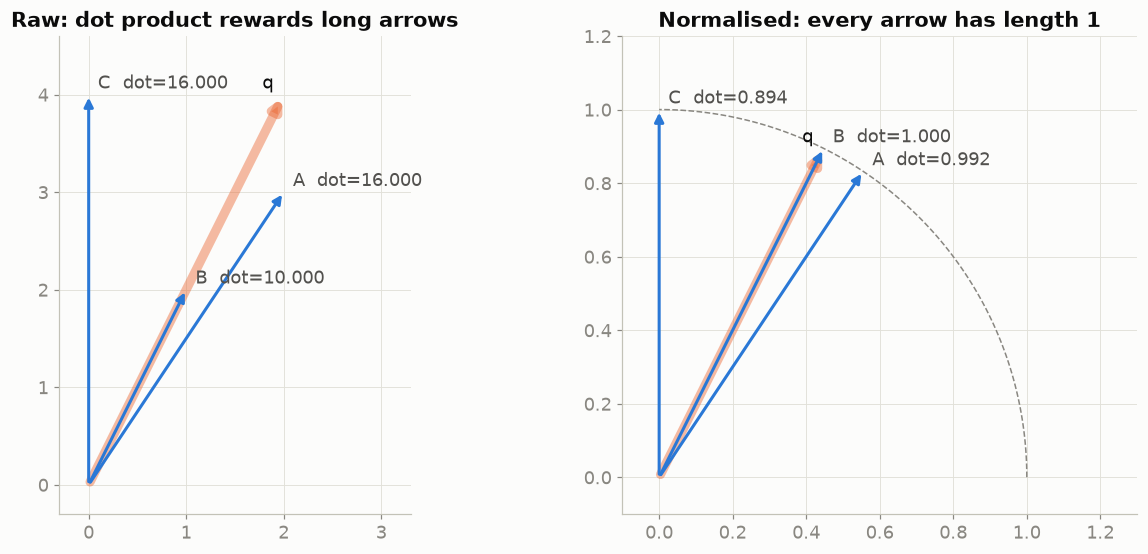

In [75]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2))  # before and after, side by side
arc = np.linspace(0, np.pi / 2, 100)                     # angles for drawing a quarter of the unit circle
for ax, vecs, qv, title in [(ax1, P2, q2, "Raw: dot product rewards long arrows"),           # left panel
                            (ax2, P2n, q2n, "Normalised: every arrow has length 1")]:       # right panel
    ax.annotate("", xy=qv, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=6, alpha=0.45))  # the query, wide
    for name, v in zip(names, vecs):                     # each stored vector
        ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2))   # arrow from the origin
        ax.annotate(f"{name}  dot={v @ qv:.3f}", v, textcoords="offset points", xytext=(6, 4), color=INK2)   # dot product label
    ax.annotate("q", qv, textcoords="offset points", xytext=(-14, 4))   # query label
    ax.set_title(title); ax.set_aspect("equal")          # title, equal axis scale
ax2.plot(np.cos(arc), np.sin(arc), color=MUTED, lw=1, ls="--")   # unit circle: every normalised arrow ends on it
ax1.set_xlim(-0.3, 3.3); ax1.set_ylim(-0.3, 4.6)         # left view
ax2.set_xlim(-0.1, 1.3); ax2.set_ylim(-0.1, 1.2)         # right view (zoomed in to the unit circle)
plt.tight_layout(); plt.show()                           # render

Now the 1,000 vectors in 3072 dimensions. Each query gets four rankings:
cosine, dot product on normalised vectors, Euclidean on normalised vectors, and dot product on **raw** vectors.

In [76]:
Xn, Qn = normalise(X), normalise(Q)                      # normalised copies of stored and query vectors
print(f"lengths before: {lengths.min():.3f} .. {lengths.max():.3f}   "   # range of lengths before...
      f"after: {np.linalg.norm(Xn, axis=1).min():.4f} .. {np.linalg.norm(Xn, axis=1).max():.4f}")   # all 1.0 after


def ranking(scores, largest=True, k=10):                 # top-10 row numbers for a score array
    return np.argsort(-scores if largest else scores, kind="stable")[:k].tolist()   # stable sort keeps ties in id order


rows = []                                                # one row per query
for qi, qv in enumerate(Q):                              # each query
    cos_scores = X @ qv / (lengths * np.linalg.norm(qv)) # cosine from the formula, on raw vectors
    unit_dot = Xn @ Qn[qi]                               # plain dot product on normalised vectors
    unit_euc = np.linalg.norm(Xn - Qn[qi], axis=1)       # Euclidean distance on normalised vectors
    raw_dot = X @ qv                                     # plain dot product on raw vectors
    r_cos = ranking(cos_scores)                          # the reference ranking
    rows.append({                                        # compare everything with cosine
        "query": qi,                                     # query number
        "cosine top-10": r_cos,                          # reference
        "dot (normalised) same?": ranking(unit_dot) == r_cos,                 # expected: True
        "Euclidean (normalised) same?": ranking(unit_euc, largest=False) == r_cos,   # expected: True
        "dot (raw) same?": ranking(raw_dot) == r_cos,                         # expected: False (lengths interfere)
        "max |cosine - normalised dot|": float(np.abs(cos_scores - unit_dot).max()),  # numbers equal up to rounding
    })
pd.DataFrame(rows).set_index("query")                   # show the table

lengths before: 1.000 .. 1.000   after: 1.0000 .. 1.0000


,cosine top-10,dot (normalised) same?,Euclidean (normalised) same?,dot (raw) same?,max |cosine - normalised dot|
query,,,,,
0,"[157, 321, 379, 844, 968, 788, 215, 411, 91, 294]",True,True,True,1.1921e-07
1,"[527, 0, 35, 480, 512, 464, 374, 487, 321, 232]",True,True,True,1.7881e-07
2,"[839, 58, 145, 64, 454, 868, 375, 683, 316, 597]",True,True,True,1.7881e-07
3,"[35, 953, 723, 775, 690, 877, 711, 480, 853, 71]",True,True,True,1.1921e-07
4,"[711, 927, 512, 48, 514, 857, 633, 929, 227, 685]",True,True,True,1.1921e-07


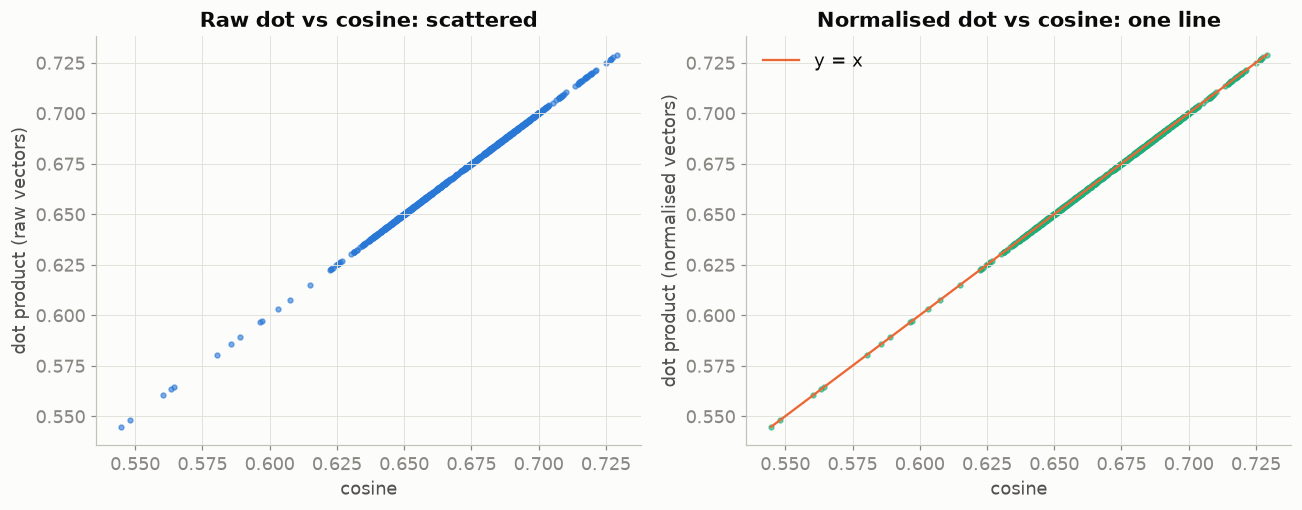

In [77]:
cos0 = X @ q0 / (lengths * np.linalg.norm(q0))           # cosine of query 0 with every stored vector
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))  # two scatter plots
ax1.scatter(cos0, X @ q0, s=10, color=BLUE, alpha=0.6)   # x = cosine, y = raw dot product
ax1.set_title("Raw dot vs cosine: scattered")            # vectors with equal cosine get very different raw dots
ax1.set_xlabel("cosine"); ax1.set_ylabel("dot product (raw vectors)")    # axis labels
ax2.scatter(cos0, Xn @ Qn[0], s=10, color=AQUA, alpha=0.6)               # x = cosine, y = dot on normalised vectors
lim = [cos0.min(), cos0.max()]                           # range for the reference line
ax2.plot(lim, lim, color=ORANGE, lw=1.5, label="y = x")  # perfect agreement line
ax2.set_title("Normalised dot vs cosine: one line")      # every point lies on y = x
ax2.set_xlabel("cosine"); ax2.set_ylabel("dot product (normalised vectors)")   # axis labels
ax2.legend(frameon=False)                                # legend for the y = x line
plt.tight_layout(); plt.show()                           # render

**The same check inside Qdrant:** `COSINE` on the raw vectors vs `DOT` on the normalised vectors (they should be identical),
and `DOT` on the raw vectors (it should differ).

In [78]:
C4 = "part4_normalise"                                   # collection name for this part
if client.collection_exists(C4):                         # left over from an earlier run?
    client.delete_collection(C4)                         # start clean
client.create_collection(C4, vectors_config={            # three named vectors per point
    "cos_raw": models.VectorParams(size=DIM, distance=models.Distance.COSINE),   # cosine on raw vectors
    "dot_unit": models.VectorParams(size=DIM, distance=models.Distance.DOT),     # dot product on normalised vectors
    "dot_raw": models.VectorParams(size=DIM, distance=models.Distance.DOT),      # dot product on raw vectors
})
upload(C4, {"cos_raw": X, "dot_unit": Xn, "dot_raw": X}) # raw, normalised, raw

exact = models.SearchParams(exact=True)                  # full scan, so only the formula matters
rows = []                                                # one row per query
for qi in range(len(Q)):                                 # each query
    a = client.query_points(C4, query=Q[qi].tolist(), using="cos_raw", limit=10, search_params=exact).points    # COSINE, raw
    b = client.query_points(C4, query=Qn[qi].tolist(), using="dot_unit", limit=10, search_params=exact).points  # DOT, normalised
    c = client.query_points(C4, query=Q[qi].tolist(), using="dot_raw", limit=10, search_params=exact).points    # DOT, raw
    ids = lambda pts: [p.id for p in pts]                # helper: just the ids
    rows.append({"query": qi,                            # record
                 "DOT(normalised) == COSINE(raw)": ids(a) == ids(b),               # expected: True
                 "max score diff": max(abs(x.score - y.score) for x, y in zip(a, b)),  # ~1e-7
                 "DOT(raw) == COSINE(raw)": ids(c) == ids(a)})                     # expected: False
pd.DataFrame(rows).set_index("query")                   # show the table

,DOT(normalised) == COSINE(raw),max score diff,DOT(raw) == COSINE(raw)
query,,,
0,True,1.1921e-07,True
1,True,1.1921e-07,True
2,True,1.7881e-07,True
3,True,2.3842e-07,True
4,True,5.9605e-08,True


**Takeaways**

- After normalising, **cosine = dot product = (a monotone function of) Euclidean**, and all three give one ranking.
- The raw dot product gives a *different* ranking, because it mixes direction with length.
- This is exactly how Qdrant implements `COSINE`: it **normalises each vector once, on insert**, and every search is then a plain dot product, which is cheaper.
- Gemini Embedding 2 returns normalised vectors, so for real embeddings all three metrics already agree.

---
## Part 5: Timing, brute force vs Qdrant, at 1,000 and 10,000 vectors

For each size: 100 queries, top-10, cosine, three methods:

| method | what it does |
|---|---|
| **NumPy brute force** | one matrix-vector product + argpartition per query (vectors pre-normalised; best of 5 passes) |
| **Qdrant exact** | Qdrant scans every vector (`exact=True`) |
| **Qdrant HNSW** | Qdrant walks its graph index (`exact=False`, shortlist `hnsw_ef=64`) |

**Two Qdrant times.** The *round trip* is the wall-clock time in Python: network + HTTP + JSON + search. The *server time* is the `time` field Qdrant puts in every REST response: the search alone.
On a cloud cluster the round trip is mostly network delay, so **server time is the fair comparison with NumPy**.

**Recall@10** = the share of NumPy's exact top-10 that HNSW also returned (1.0 = perfect).

The 10,000 vectors are synthetic, because embedding 10,000 real chunks would exceed the API's daily token limit. Search speed depends only on how many vectors there are and their size, not on what the text says.

*This part uploads 11,000 vectors, so it takes a minute or two.*

In [79]:
C5 = "part5_benchmark"                                   # collection name for the benchmark
N_QUERIES = 100                                          # queries per measurement
K5 = 10                                                  # top-10


def make_queries(X, n=N_QUERIES, seed=1):  # X: the stored vectors to draw queries from
    """Benchmark queries: random stored vectors + a little noise, so every query has close neighbours."""
    rng = np.random.default_rng(seed)                    # seeded, so runs are repeatable
    base = normalise(X[rng.choice(len(X), n, replace=False)])           # 100 distinct stored vectors, length 1
    return (base + rng.normal(scale=0.5 / np.sqrt(X.shape[1]), size=base.shape)).astype(np.float32)   # nudge each one


def numpy_search(Xn, qv, k=K5):  # Xn: normalised stored vectors, qv: one query
    """Cosine top-k by brute force on pre-normalised vectors: one dot product per stored vector."""
    s = Xn @ (qv / np.linalg.norm(qv))                   # cosines = dot products, because Xn is normalised
    idx = np.argpartition(-s, k)[:k]                     # the k best, unordered
    return idx[np.argsort(-s[idx])].tolist()             # ordered, best first


def build_benchmark_collection(X):  # X: the vectors to load
    """Fresh collection with a forced HNSW index; returns (upload seconds, index-build seconds)."""
    if client.collection_exists(C5):                     # left over from the previous size?
        client.delete_collection(C5)                     # start clean
    client.create_collection(                            # define the collection
        collection_name=C5,                              # its name
        vectors_config=models.VectorParams(size=DIM, distance=models.Distance.COSINE),   # one cosine vector per point
        optimizers_config=models.OptimizersConfigDiff(   # how the data is organised
            indexing_threshold=10,                       # build HNSW even for small data
            default_segment_number=2,                    # 2 segments; the default (one per CPU core) means many small graphs
        ),                                               # end of optimizer settings
        hnsw_config=models.HnswConfigDiff(m=16, ef_construct=100, full_scan_threshold=10),   # 16 links per node; HNSW always used
    )
    t0 = time.perf_counter()                             # start the clock
    upload(C5, X)                                        # load the vectors
    t_upload = time.perf_counter() - t0                  # upload time
    wait_until_indexed(C5, len(X))                       # wait for the HNSW graph to be built
    return t_upload, time.perf_counter() - t0 - t_upload # (upload time, extra time to finish the index)


http = requests.Session()                                # one reusable HTTP connection for raw REST calls
if QDRANT_API_KEY:                                       # Qdrant Cloud needs the key on every request
    http.headers["api-key"] = QDRANT_API_KEY             # header name Qdrant expects


def qdrant_rest_search(Qs, exact):  # Qs: the queries, exact: scan (True) or HNSW (False)
    """Run every query through Qdrant's REST API; return (ids per query, round-trip s, server s)."""
    url = f"{QDRANT_URL}/collections/{C5}/points/query"  # REST search endpoint
    ids, round_trip, server = [], [], []                 # results and timings
    for qv in Qs:                                        # one request per query (like a real user)
        body = {"query": qv.tolist(), "limit": K5, "params": {"exact": exact, "hnsw_ef": 64}}   # same search as Part 3
        t0 = time.perf_counter()                         # start the wall clock
        r = http.post(url, json=body, timeout=60)        # send the request
        round_trip.append(time.perf_counter() - t0)      # wall-clock time including the network
        r.raise_for_status()                             # stop loudly on errors
        reply = r.json()                                 # parse the response
        server.append(reply["time"])                     # Qdrant's own measurement of the search, in seconds
        ids.append([p["id"] for p in reply["result"]["points"]])   # returned ids, best first
    return ids, round_trip, server                       # everything we need

In [80]:
def benchmark(X, label):  # X: stored vectors, label: name for the results table
    """Time NumPy vs Qdrant exact vs Qdrant HNSW on one set of stored vectors."""
    Xn_b = normalise(X)                                  # NumPy works on normalised vectors (cosine = dot)
    Qb = make_queries(X)                                 # 100 benchmark queries
    t_upload, t_index = build_benchmark_collection(X)    # load into Qdrant and build HNSW

    qdrant_rest_search(Qb[:20], exact=False)             # warm-up: first queries load data into memory
    qdrant_rest_search(Qb[:20], exact=True)              # warm-up for the exact path too

    ex_ids, ex_rt, ex_srv = qdrant_rest_search(Qb, exact=True)    # Qdrant full scan
    hn_ids, hn_rt, hn_srv = qdrant_rest_search(Qb, exact=False)   # Qdrant HNSW

    np_runs = []                                         # timed after Qdrant, when its background work has finished
    for _ in range(5):                                   # NumPy is fast enough to be noisy, so take the best of 5 passes
        t0 = time.perf_counter()                         # start
        np_ids = [numpy_search(Xn_b, qv) for qv in Qb]   # brute-force every query
        np_runs.append((time.perf_counter() - t0) / len(Qb))   # seconds per query

    ms = lambda v: 1000 * statistics.median(v)           # seconds -> milliseconds, median over the 100 queries
    return {                                             # one result row
        "vectors": label,                                # 1,000 or 10,000
        "NumPy (ms)": 1000 * min(np_runs),               # best of the 5 NumPy passes
        "Qdrant exact, server (ms)": ms(ex_srv),         # search alone, full scan
        "Qdrant HNSW, server (ms)": ms(hn_srv),          # search alone, graph
        "Qdrant exact, round trip (ms)": ms(ex_rt),      # including HTTP/network
        "Qdrant HNSW, round trip (ms)": ms(hn_rt),       # including HTTP/network
        "HNSW recall@10": statistics.mean(len(set(a) & set(b)) / K5 for a, b in zip(np_ids, hn_ids)),   # share of true top-10 found
        "exact = NumPy": f"{sum(a == b for a, b in zip(np_ids, ex_ids))}/{len(Qb)}",   # how many identical top-10 lists
        "upload (s)": t_upload,                          # time to load the vectors
        "index build (s)": t_index,                      # extra time to finish the HNSW graph
    }


X10k, _ = synthetic_vectors(10_000, seed=7)              # 10,000 synthetic vectors (different seed = new data)
timing = pd.DataFrame([benchmark(X, "1,000"),            # run at 1,000 vectors
                       benchmark(X10k, "10,000")]).set_index("vectors")   # and at 10,000
client.delete_collection(C5)                             # free the memory on the server
timing.round(3)                                          # show the results

,NumPy (ms),"Qdrant exact, server (ms)","Qdrant HNSW, server (ms)","Qdrant exact, round trip (ms)","Qdrant HNSW, round trip (ms)",HNSW recall@10,exact = NumPy,upload (s),index build (s)
vectors,,,,,,,,,
"1,000",0.193,0.951,0.762,367.723,367.947,1.000,100/100,13.272,0.335
"10,000",2.863,7.156,0.870,368.428,367.973,0.997,100/100,125.702,1.665


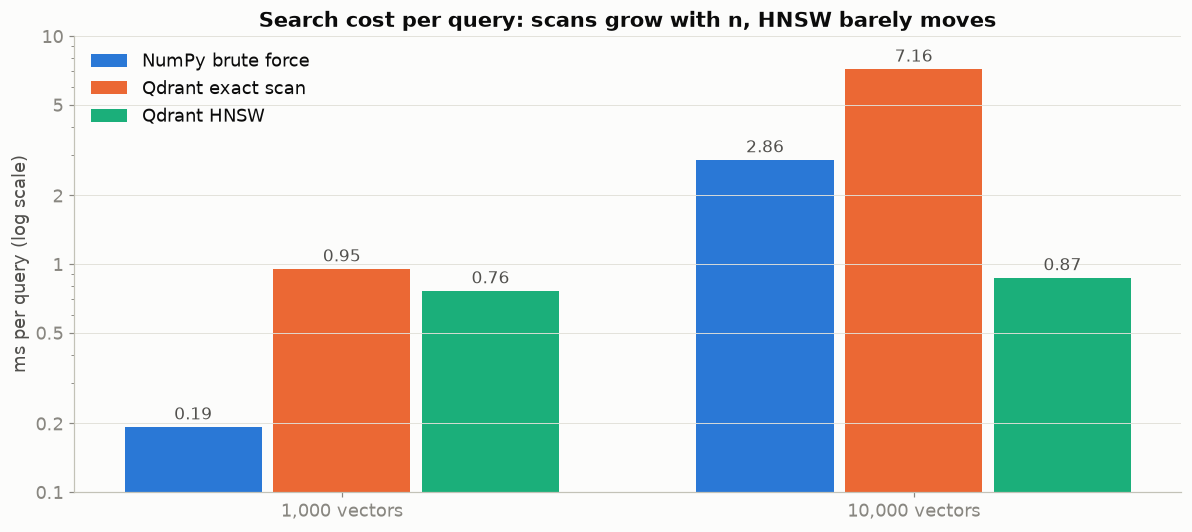

In [81]:
cols = [("NumPy brute force", "NumPy (ms)", BLUE),               # (legend name, column, colour): NumPy
        ("Qdrant exact scan", "Qdrant exact, server (ms)", ORANGE),      # Qdrant full scan, server time
        ("Qdrant HNSW", "Qdrant HNSW, server (ms)", AQUA)]               # Qdrant graph search, server time
x = np.arange(len(timing))                                       # one group of bars per collection size
w = 0.26                                                         # bar width
fig, ax = plt.subplots(figsize=(11, 5))                          # one wide chart
for i, (name, col, colour) in enumerate(cols):                   # three bars per group
    vals = timing[col].values                                    # times for 1,000 and 10,000
    bars = ax.bar(x + (i - 1) * w, vals, w - 0.02, color=colour, label=name)   # draw with a small gap between bars
    for b, v in zip(bars, vals):                                 # write the value above each bar
        ax.text(b.get_x() + b.get_width() / 2, v * 1.08, f"{v:.2f}", ha="center", color=INK2, fontsize=11)   # centred, just above
ax.set_xticks(x, [f"{v} vectors" for v in timing.index])         # group labels
ax.set_yscale("log")                                             # log scale: shows 0.1 ms and 20 ms on one axis
ticks = [t for t in (0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100)   # candidate tick values in ms...
         if timing[[c for _, c, _ in cols]].values.min() / 2 <= t <= timing[[c for _, c, _ in cols]].values.max() * 2]   # ...keep those in range
ax.set_yticks(ticks, [f"{t:g}" for t in ticks])                  # plain labels (0.5, 1, 2) instead of 5x10^-1
ax.yaxis.set_minor_formatter(plt.NullFormatter())                # hide the cluttered minor-tick labels
ax.set_ylabel("ms per query (log scale)")                        # y axis
ax.set_title("Search cost per query: scans grow with n, HNSW barely moves")   # the message
ax.legend(frameon=False, loc="upper left")                       # legend
ax.grid(axis="x", visible=False)                                 # no vertical gridlines
plt.tight_layout(); plt.show()                                   # render

**How to read the timings**

- **NumPy and Qdrant's exact scan grow linearly with n.** 10× the vectors means about 10× the work ($n \times d$ multiply-adds).
- **HNSW stays almost flat.** It scores only a few hundred vectors whatever *n* is. At 10,000 vectors it already beats both scans, and the gap keeps widening: at millions of vectors a scan takes seconds and HNSW still takes milliseconds.
- **At 1,000 vectors brute force is perfectly fine,** even fastest. One small matrix product is cheap, and Qdrant's own request handling costs more than the search.
- **Recall@10 slightly below 1.0** is the price of HNSW: it is *approximate* and can occasionally miss a true neighbour.
- **The round-trip columns** show what a client actually waits for. Against Qdrant Cloud they are dominated by network delay (tens to hundreds of ms).

---
## Part 6: What an HNSW index changes

**HNSW = Hierarchical Navigable Small World.** It does **not** change the score formula. It changes **which vectors get scored**.

**Without an index (brute force):** every query is compared with all *n* vectors. Cost ∝ *n × d*, and the answer is exact.

**With HNSW:**

1. **At insert time a graph is built.** Each vector is linked to about `m` = 16 of its nearest neighbours.
   A few sparser **upper layers** hold a random subset of vectors with long-distance links, like express lanes on a motorway.
2. **At query time the search is greedy.** It starts at an entry point on the top layer and repeatedly **hops to whichever neighbour is closer to the query**.
   When no neighbour is closer it drops one layer. On the bottom layer it keeps a shortlist of the `ef` best candidates seen so far, and returns the top *k*.
3. **Result:** only a few hundred vectors are scored instead of all *n*, so the cost grows roughly with **log n** instead of *n*.

**What it costs:**

- **Approximate answers.** The greedy walk can miss a true neighbour (recall < 1).
- **Build time and memory** for the graph (Part 5's "index build" column).
- **Tuning knobs** that trade recall against speed and memory: `m` (links per node), `ef_construct` (care taken while building), `hnsw_ef` (shortlist size at query time).

**In Qdrant specifically:** segments smaller than `indexing_threshold` / `full_scan_threshold` (about 10 MB by default) are **not indexed** but simply scanned, because at that size a scan is cheaper.
`exact=True` forces a scan, which is how recall is measured.

Below is a **one-layer toy HNSW in 2D**, so the greedy walk can be drawn:

In [82]:
rng = np.random.default_rng(3)                           # seeded, so the picture is the same every run
pts = rng.uniform(0, 10, size=(400, 2))                  # 400 stored "vectors" in 2D
query = np.array([8.3, 7.6])                             # the query point

# ---- build the index: link every point to its 6 nearest neighbours
D = np.linalg.norm(pts[:, None] - pts[None], axis=2)     # 400x400 table of all pairwise distances (fine for a toy)
nbrs = np.argsort(D, axis=1)[:, 1:7]                     # for each point, its 6 closest others (column 0 is itself)

# ---- search: greedy walk from an entry point towards the query
cur = 0                                                  # entry point: just point 0
path = [cur]                                             # points visited, in order
scored = {cur}                                           # every point whose distance to the query we computed
while True:                                              # keep hopping...
    cand = nbrs[cur]                                     # neighbours of the current point
    scored.update(cand.tolist())                         # computing their distances = scoring them
    best = cand[np.argmin(np.linalg.norm(pts[cand] - query, axis=1))]   # the neighbour closest to the query
    if np.linalg.norm(pts[best] - query) >= np.linalg.norm(pts[cur] - query):   # no neighbour is closer than where we are?
        break                                            # then stop: this is the answer
    cur = best                                           # otherwise move there
    path.append(cur)                                     # and remember the hop

true_nn = int(np.argmin(np.linalg.norm(pts - query, axis=1)))   # brute-force answer, for comparison
print(f"greedy search found point {cur}; true nearest point is {true_nn}: "   # graph answer vs brute-force answer...
      f"{'correct' if cur == true_nn else 'missed (approximate!)'}")   # did the shortcut work?
print(f"work: {len(scored)} distance computations instead of {len(pts)} ({len(scored) / len(pts):.0%})")   # the saving

greedy search found point 145; true nearest point is 145: correct
work: 63 distance computations instead of 400 (16%)


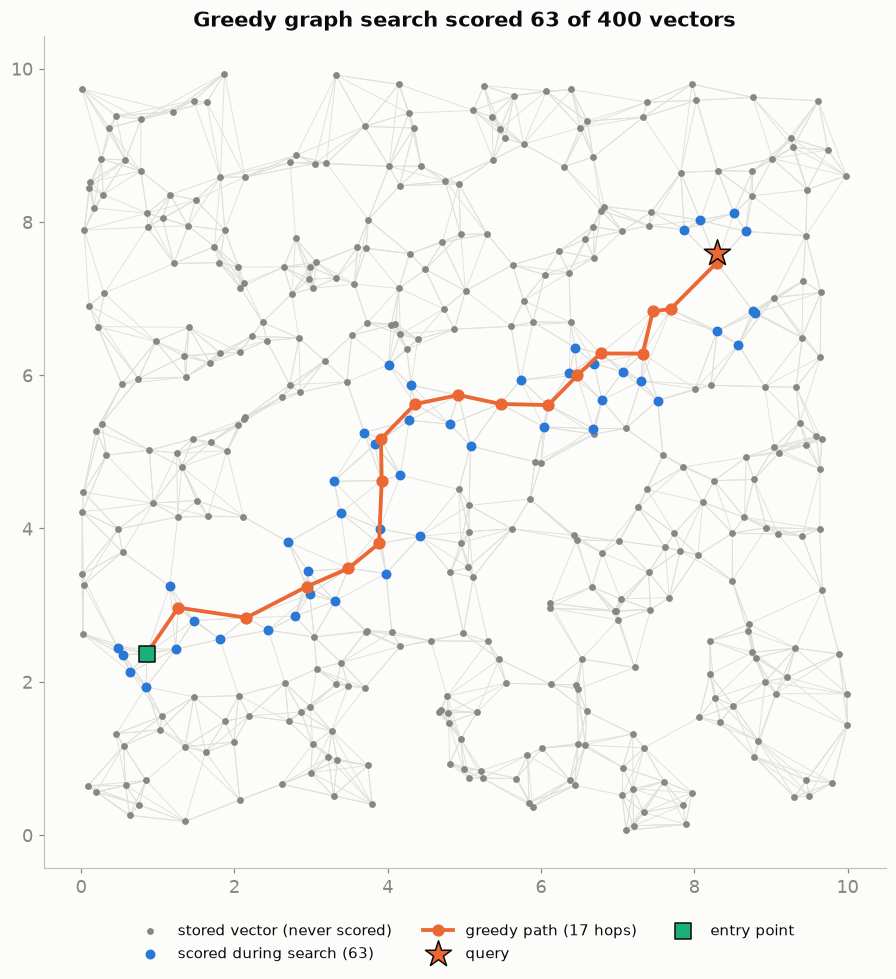

In [83]:
fig, ax = plt.subplots(figsize=(9, 9))                   # square plot
for i in range(len(pts)):                                # draw the graph edges
    for j in nbrs[i]:                                    # each link of point i
        ax.plot(*pts[[i, j]].T, color=GRID, lw=0.6, zorder=1)   # thin light line
ax.scatter(*pts.T, s=12, color=MUTED, zorder=2, label="stored vector (never scored)")    # all points in grey
sc = np.array(sorted(scored))                            # the points the search actually scored
ax.scatter(*pts[sc].T, s=30, color=BLUE, zorder=3, label=f"scored during search ({len(sc)})")   # scored points in blue
ax.plot(*pts[path].T, color=ORANGE, lw=2.5, marker="o", ms=7, zorder=4, label=f"greedy path ({len(path) - 1} hops)")  # the walk
ax.scatter(*query, s=320, marker="*", color=ORANGE, edgecolor=INK, zorder=5, label="query")           # the query
ax.scatter(*pts[path[0]], s=120, marker="s", color=AQUA, edgecolor=INK, zorder=5, label="entry point")  # where it started
ax.set_title(f"Greedy graph search scored {len(sc)} of {len(pts)} vectors")   # the message
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=3, fontsize=10)   # legend below the plot
ax.set_aspect("equal"); ax.grid(False)                   # equal scale, no grid (the graph is the grid)
plt.tight_layout(); plt.show()                           # render

The walk went straight across the graph and scored only the blue points. That is the whole idea of HNSW.
Real HNSW adds the upper "express lane" layers (fewer hops on huge collections) and a candidate shortlist (`ef`) instead of a single greedy path, which makes misses much rarer.

---
## Part 7: Summary

| Question | Answer shown in this notebook |
|---|---|
| What does a vector DB compute? | The same dot products, cosines and distances we wrote by hand in Part 1 |
| Euclidean vs cosine? | Euclidean measures the gap (cares about length); cosine measures direction only, so they can rank differently (B in Part 1) |
| Does Qdrant match NumPy? | Yes: the same ids, order and scores in all 20 comparisons (Part 3); differences ~1e-7 are float32 rounding |
| Why normalise? | On unit vectors cosine = dot product, so the ranking is identical; Qdrant's COSINE normalises on insert and then uses dot (Part 4) |
| Brute force vs index? | Brute force is exact and grows with *n*; HNSW scores a few hundred vectors, stays almost flat, and is approximate (Parts 5 and 6) |

| | Brute force (no index) | HNSW index |
|---|---|---|
| Vectors scored per query | all *n* | a few hundred, found by walking a graph |
| Cost per query | ∝ *n × d* | ≈ ∝ log *n* |
| Answer | exact | approximate (recall just below 1) |
| Extra cost | none | graph build time and memory |
| Best for | small collections, ground truth | large collections, low latency |

**A vector database does nothing magic. The index only decides *which* vectors are worth scoring.**

In [84]:
for name in (C3, C4):                                    # collections created by this notebook
    if client.collection_exists(name):                   # still there?
        client.delete_collection(name)                   # remove it, to free memory on the server
print("cleaned up Qdrant collections created by this notebook")   # done

cleaned up Qdrant collections created by this notebook
